In [11]:
from pathlib import Path
import os

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDLEAD")
os.chdir(repo_root)

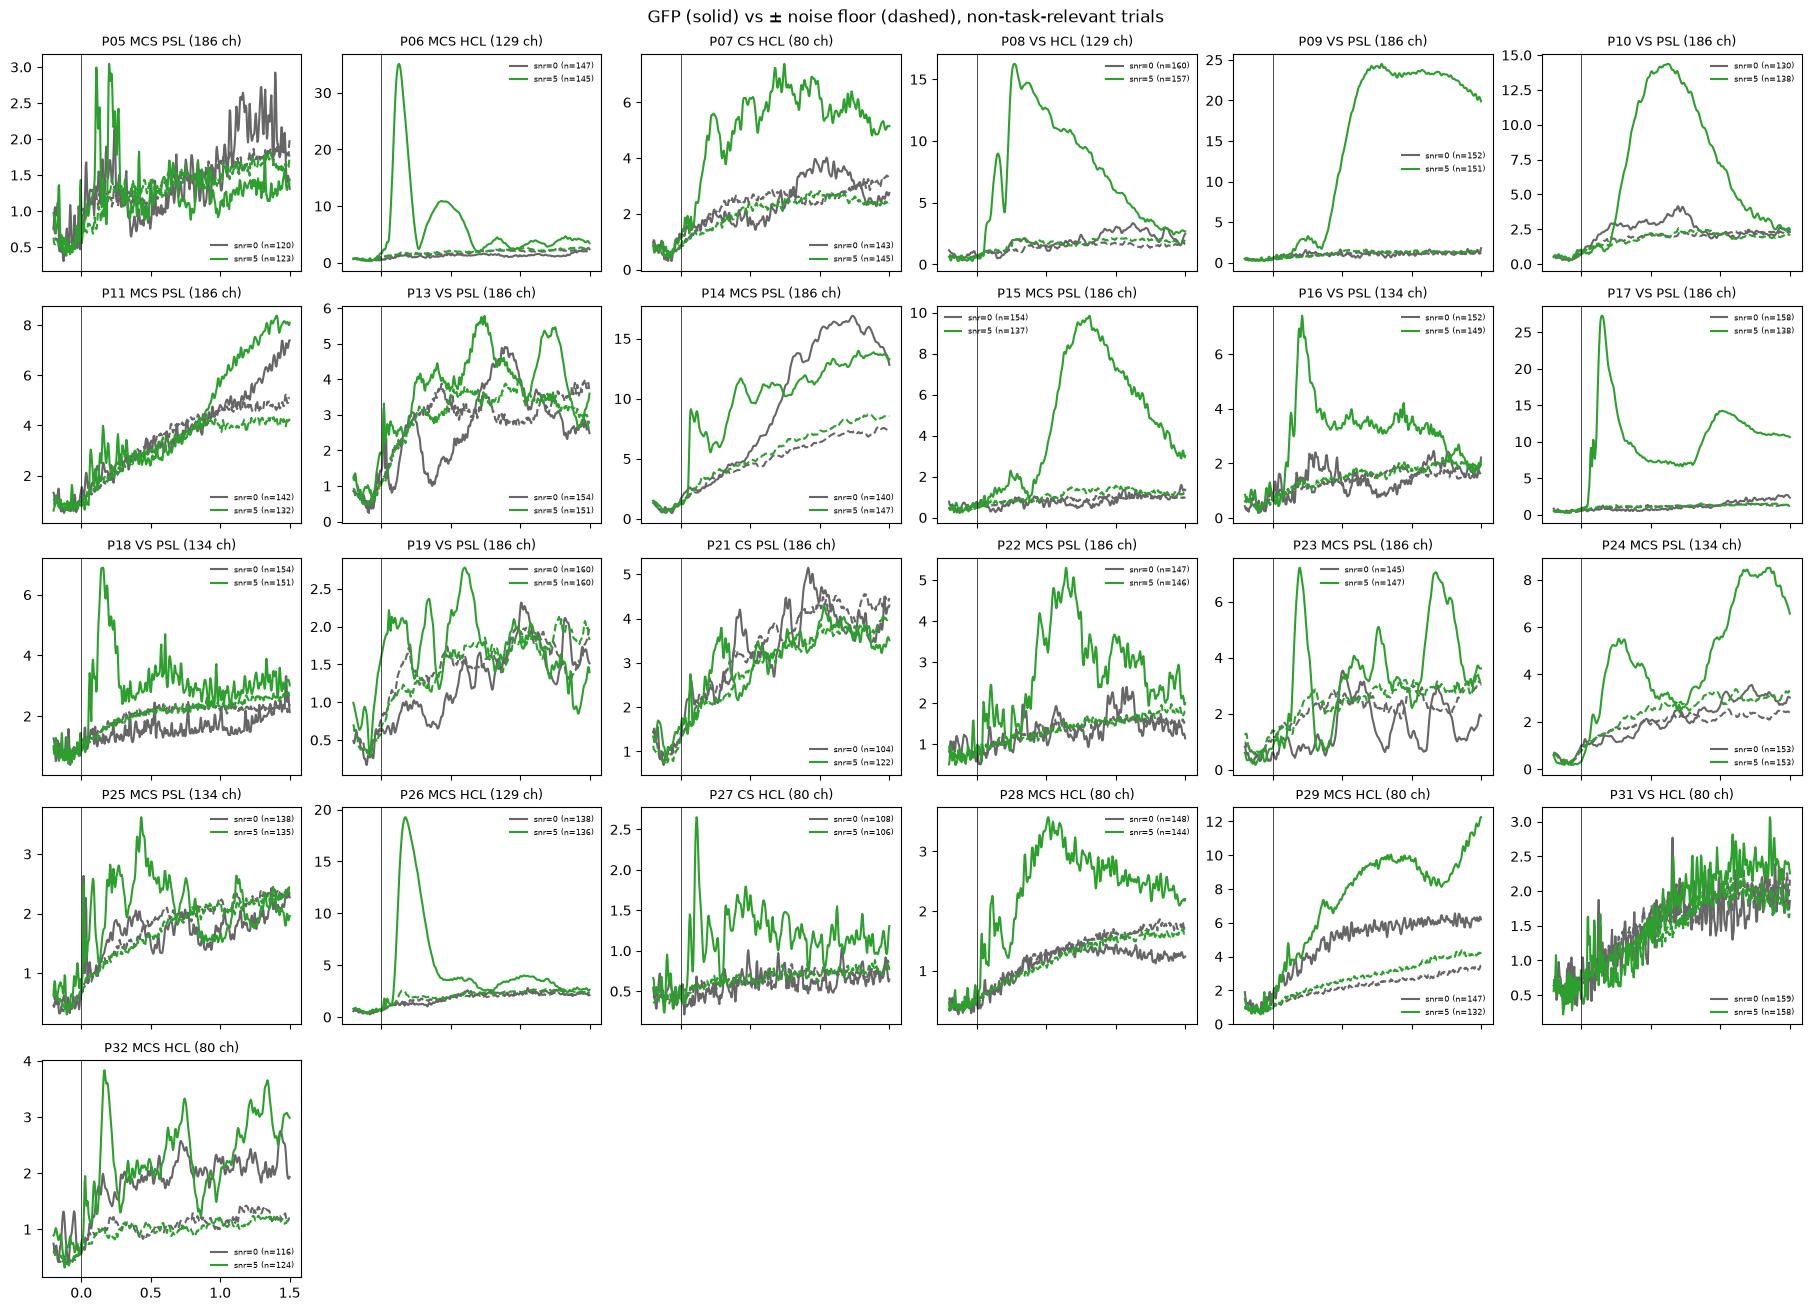

snr           0      5
group sub             
CS    P07  1.06   2.20
      P21  0.92   0.99
      P27  0.91   1.47
MCS   P05  1.19   0.80
      P06  0.72   1.54
      P11  1.21   1.77
      P14  2.21   1.63
      P15  1.09   4.00
      P22  1.02   1.56
      P23  0.63   1.57
      P24  1.33   2.52
      P25  0.86   0.92
      P26  1.04   1.26
      P28  0.75   1.52
      P29  2.01   2.44
      P32  1.74   2.47
VS    P08  1.62   1.91
      P09  1.14  16.73
      P10  0.99   2.00
      P13  0.90   1.24
      P16  1.15   1.39
      P17  1.50   8.66
      P18  0.85   1.17
      P19  1.01   0.81
      P31  0.92   1.22

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

EP_DIR = repo_root / "Study3" / "epochs" / "hp0.3_lp40"
BL = (-0.2, 0.0)


def gfp_vs_floor(ep, cond_col="snr", seed=0, n_perm=20):
    rng = np.random.default_rng(seed)
    ep = ep[~ep.metadata["task_relevant"].astype(bool).to_numpy()]
    t = ep.times
    X = ep.get_data(picks="eeg")
    X = X - X[:, :, (t >= BL[0]) & (t < BL[1])].mean(-1, keepdims=True)
    rms = lambda a: np.sqrt((a ** 2).mean(0)) * 1e6
    out = {}
    for c in sorted(ep.metadata[cond_col].unique()):
        Xc = X[(ep.metadata[cond_col] == c).to_numpy()]
        s = rng.permutation(np.r_[np.ones(len(Xc) // 2), -np.ones(len(Xc) - len(Xc) // 2)])
        fl = np.median([rms((rng.permutation(s)[:, None, None] * Xc).mean(0)) for _ in range(n_perm)], axis=0)
        out[c] = (rms(Xc.mean(0)), fl, len(Xc))
    return t, out


files = sorted(EP_DIR.glob("P*-epo.fif"))
fig, axes = plt.subplots(int(np.ceil(len(files) / 6)), 6, figsize=(18, 2.6 * np.ceil(len(files) / 6)),
                         sharex=True, squeeze=False, layout="constrained")
rows = []
for ax, f in zip(axes.flat, files):
    sub = f.name.replace("-epo.fif", "")
    ep = mne.read_epochs(f, preload=True, verbose="error")
    info = json.loads((EP_DIR / f"{sub}_qc.json").read_text())
    t, out = gfp_vs_floor(ep)
    late = (t >= 1.0) & (t <= 1.5)
    for c, col in [(0, "0.4"), (max(out), "tab:green")]:
        g, fl, n = out[c]
        ax.plot(t, g, color=col, label=f"snr={c} (n={n})")
        ax.plot(t, fl, color=col, ls="--")
        rows.append({"sub": sub, "group": info.get("group"), "site": info.get("site"), "snr": c,
                     "gfp_late": g[late].mean(), "floor_late": fl[late].mean(),
                     "ratio_late": g[late].mean() / fl[late].mean()})
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"{sub} {info.get('group')} {info.get('site')} ({len(ep.ch_names)} ch)", fontsize=9)
    ax.legend(fontsize=6, frameon=False)
for ax in axes.flat[len(files):]:
    ax.axis("off")
fig.suptitle("GFP (solid) vs ± noise floor (dashed), non-task-relevant trials")
plt.show()

ratios = pd.DataFrame(rows)
ratios.pivot_table(index=["group", "sub"], columns="snr", values="ratio_late").round(2)

In [13]:
def nearest_lag(a, b):
    i = np.clip(np.searchsorted(b, a), 1, len(b) - 1)
    prev, nxt = b[i - 1] - a, b[i] - a
    return np.where(np.abs(prev) < np.abs(nxt), prev, nxt)


def din_lags(ip):
    sub = f"P{ip:02d}"
    raw = mne.io.read_raw_brainvision(repo_root / "Study3" / sub / f"{sub}.vhdr", preload=False, verbose="error")
    a = raw.annotations
    on = a.onset - (raw.first_time if a.orig_time is not None else 0.0)
    desc = np.array([str(d).split("/")[-1] for d in a.description])
    stim = np.sort(on[np.char.startswith(desc.astype(str), "S1")])
    rows = []
    for d in np.unique(desc):
        if not d.upper().startswith("DI"):
            continue
        b = np.sort(on[desc == d])
        if len(b) < 2:
            continue
        lag = nearest_lag(stim, b) * 1e3
        rows.append({"sub": sub, "din": d, "n_din": len(b), "n_stim": len(stim),
                     "median_ms": np.median(lag), "iqr_ms": np.subtract(*np.percentile(lag, [75, 25])),
                     "p5_ms": np.percentile(lag, 5), "p95_ms": np.percentile(lag, 95)})
    return rows


units = [int(p[1:]) for p in pd.read_csv(repo_root / "Study3" / "participants.tsv", sep="\t")["participant"]]
lags = pd.DataFrame([r for ip in units if (repo_root / "Study3" / f"P{ip:02d}" / f"P{ip:02d}.vhdr").exists()
                     for r in din_lags(ip)])
lags.round(1)

,sub,din,n_din,n_stim,median_ms,iqr_ms,p5_ms,p95_ms
0,P05,DI10,2,1040,-1867011.0,1762967.0,-3673501.2,-235572.6
1,P05,DI20,4,1040,-182346.0,502332.0,-608113.2,457278.8
2,P05,DI21,3,1040,54763.0,746913.0,-995637.2,616271.4
3,P05,DI30,4,1040,-183319.0,516033.5,-613237.2,457907.3
4,P05,DI31,3,1040,53750.0,746914.5,-996647.2,615255.4
...,...,...,...,...,...,...,...,...
313,P32,DI51,4,790,-105654.0,498552.5,-423628.0,377007.4
314,P32,DI52,4,790,-106030.0,499352.0,-424412.0,376033.7
315,P32,DI53,4,790,-102650.0,499480.5,-422006.0,378872.0
316,P32,DI60,400,790,-496.0,2835.0,-3704.4,5043.9


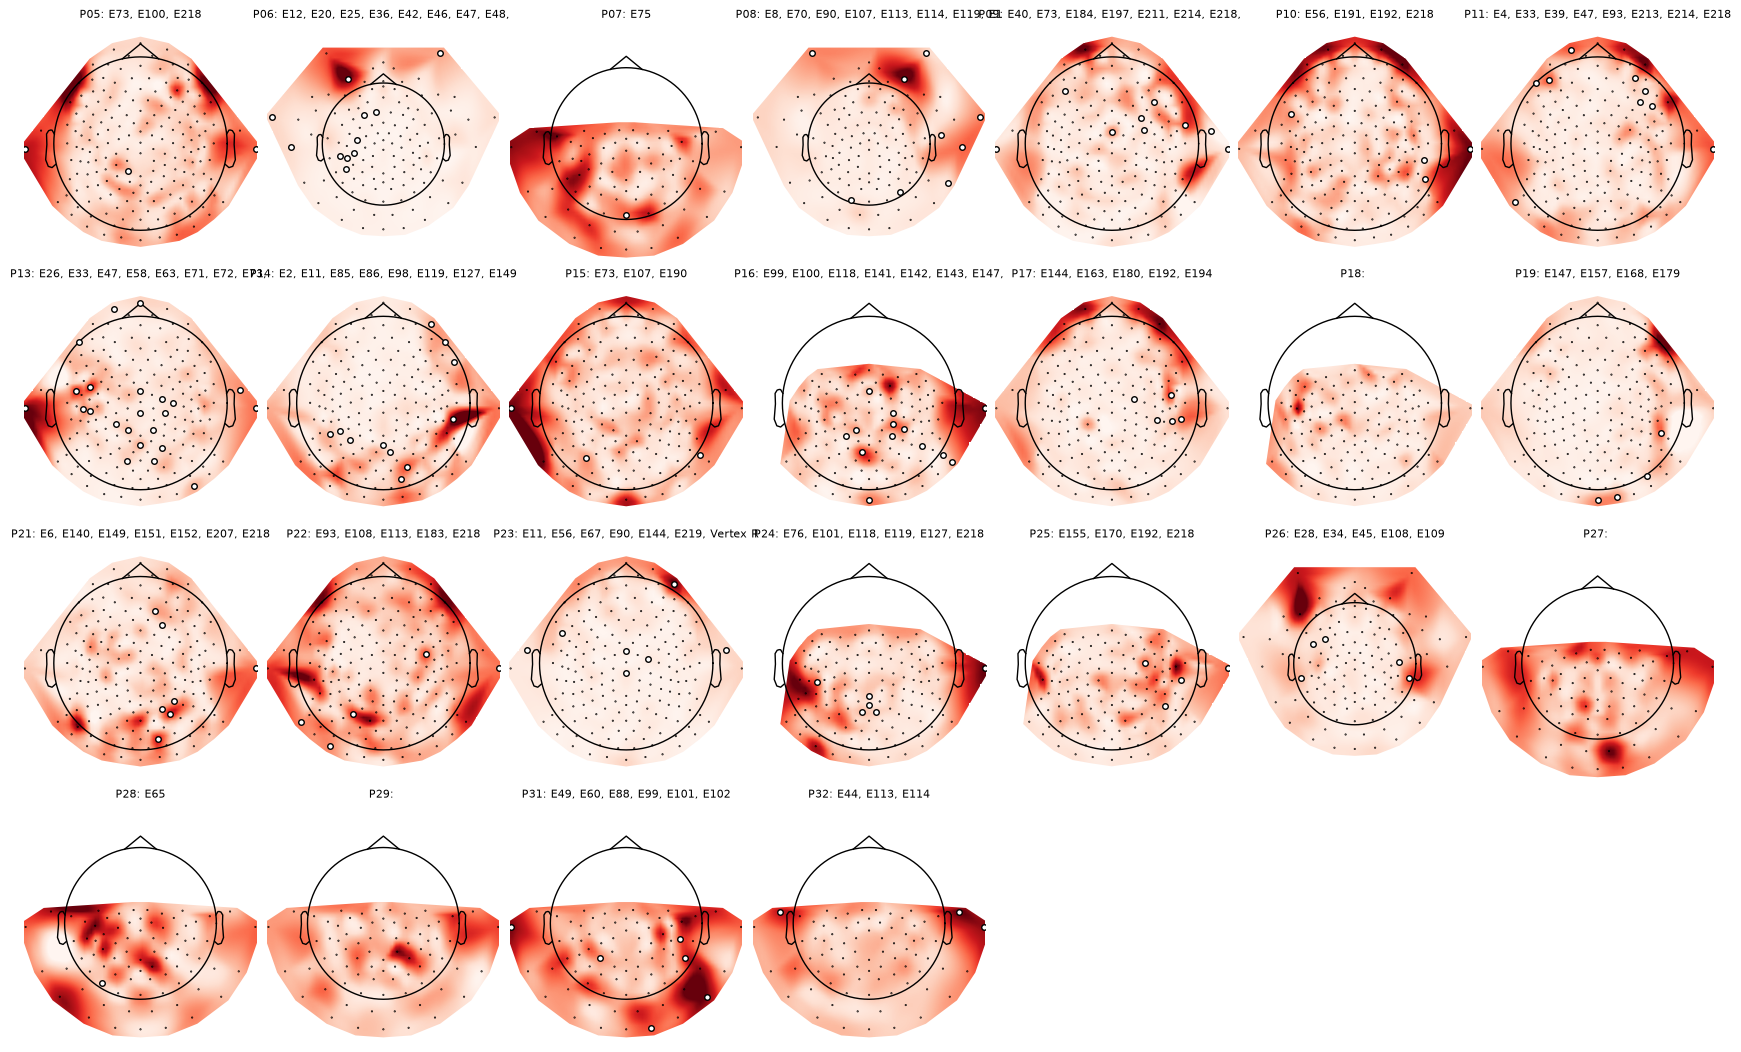

,ch,evoked_resid_uV,z_evoked,nb_corr,z_corr,sub
61,E73,1.11,2.44,0.86,-5.60,P05
179,E218,0.70,1.75,0.87,-5.21,P05
85,E100,0.32,0.57,0.88,-4.70,P05
24,E25,9.97,4.36,0.99,0.65,P06
125,E126,3.02,2.84,0.72,-7.76,P06
...,...,...,...,...,...,...
67,E102,0.61,1.06,0.73,-5.63,P31
25,E60,0.44,0.53,0.74,-5.20,P31
77,E114,1.38,4.87,0.88,-3.07,P32
76,E113,1.27,4.59,0.83,-4.80,P32


In [14]:
def robust_z(x):
    med = np.nanmedian(x)
    mad = 1.4826 * np.nanmedian(np.abs(x - med))
    return (x - med) / mad if mad > 0 else np.zeros_like(x)


def channel_outliers(ep, k=6, n_trials=200, seed=0):
    ep = ep[~ep.metadata["task_relevant"].astype(bool).to_numpy()]
    pos = np.array([ch["loc"][:3] for ch in ep.info["chs"]])
    d = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    d[np.isnan(d)] = np.inf
    np.fill_diagonal(d, np.inf)
    nb = np.argsort(d, axis=1)[:, :k]
    A = np.zeros((len(nb), len(nb)))
    A[np.repeat(np.arange(len(nb)), k), nb.ravel()] = 1 / k
    t = ep.times
    X = ep.get_data(picks="eeg")
    X = X - X[:, :, (t >= -0.2) & (t < 0)].mean(-1, keepdims=True)
    ev = X.mean(0)
    post = t >= 0
    resid = ev[:, post] - np.median(ev[nb][:, :, post], axis=1)
    evoked_rms = np.sqrt((resid ** 2).mean(1)) * 1e6
    sel = np.random.default_rng(seed).choice(len(X), min(n_trials, len(X)), replace=False)
    Xs = X[sel] - X[sel].mean(-1, keepdims=True)
    Ns = np.einsum("ij,njt->nit", A, Xs)
    nb_corr = np.median((Xs * Ns).sum(-1) / np.sqrt((Xs ** 2).sum(-1) * (Ns ** 2).sum(-1)), axis=0)
    return pd.DataFrame({"ch": ep.ch_names, "evoked_resid_uV": evoked_rms,
                         "z_evoked": robust_z(np.log(evoked_rms)), "nb_corr": nb_corr, "z_corr": robust_z(nb_corr)})


rows = []
nr = int(np.ceil(len(files) / 7))
fig, axes = plt.subplots(nr, 7, figsize=(17, 2.6 * nr), squeeze=False, layout="constrained")
for ax, f in zip(axes.flat, files):
    sub = f.name.replace("-epo.fif", "")
    ep = mne.read_epochs(f, preload=True, verbose="error")
    df = channel_outliers(ep).assign(sub=sub)
    rows.append(df)
    bad = ((df["z_evoked"] > 4) | (df["z_corr"] < -4)).to_numpy()
    mne.viz.plot_topomap(df["evoked_resid_uV"].to_numpy(), ep.info, axes=ax, show=False, contours=0, cmap="Reds",
                         mask=bad, sphere="auto", extrapolate="local")
    ax.set_title(f"{sub}: {', '.join(df.loc[bad, 'ch'])}"[:45], fontsize=8)
for ax in axes.flat[len(files):]:
    ax.axis("off")
plt.show()

flags = pd.concat(rows)
flags[(flags.z_evoked > 4) | (flags.z_corr < -4)].sort_values(["sub", "z_evoked"], ascending=[True, False]).round(2)

In [15]:
import re

def net_check(ip):
    sub = f"P{ip:02d}"
    mff = sorted(f for f in (repo_root / "Study3" / "Study3_mff" / f"P{ip}").glob("*.mff") if not f.name.startswith("."))[0]
    name = re.search(r"<name>(.*?)</name>", (mff / "sensorLayout.xml").read_text(errors="ignore"))
    dig = mne.channels.read_dig_fif(repo_root / "Study3" / sub / f"{sub}-dig.fif", verbose="error")
    info = mne.create_info(dig.ch_names, 250.0, "eeg")
    info.set_montage(dig, on_missing="ignore")
    r, o, _ = mne.bem.fit_sphere_to_headshape(info, dig_kinds=("eeg",), units="m", verbose="error")
    return {"sub": sub, "net": name[1] if name else None, "n_pos": len(dig.ch_names),
            "radius_cm": round(r * 100, 1), "origin_cm": np.round(np.asarray(o) * 100, 1)}


pd.DataFrame([net_check(ip) for ip in units if (repo_root / "Study3" / f"P{ip:02d}" / f"P{ip:02d}-dig.fif").exists()])

,sub,net,n_pos,radius_cm,origin_cm
0,P05,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
1,P06,HydroCel GSN 128 1.0,129,9.9,"[-0.0, 0.3, 3.8]"
2,P07,HydroCel GSN 128 1.0,129,9.9,"[-0.0, 0.3, 3.8]"
3,P08,HydroCel GSN 128 1.0,129,9.9,"[-0.0, 0.3, 3.8]"
4,P09,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
5,P10,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
6,P11,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
7,P13,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
8,P14,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"
9,P15,HydroCel GSN 256 1.0,257,9.7,"[-0.0, 0.2, 3.6]"


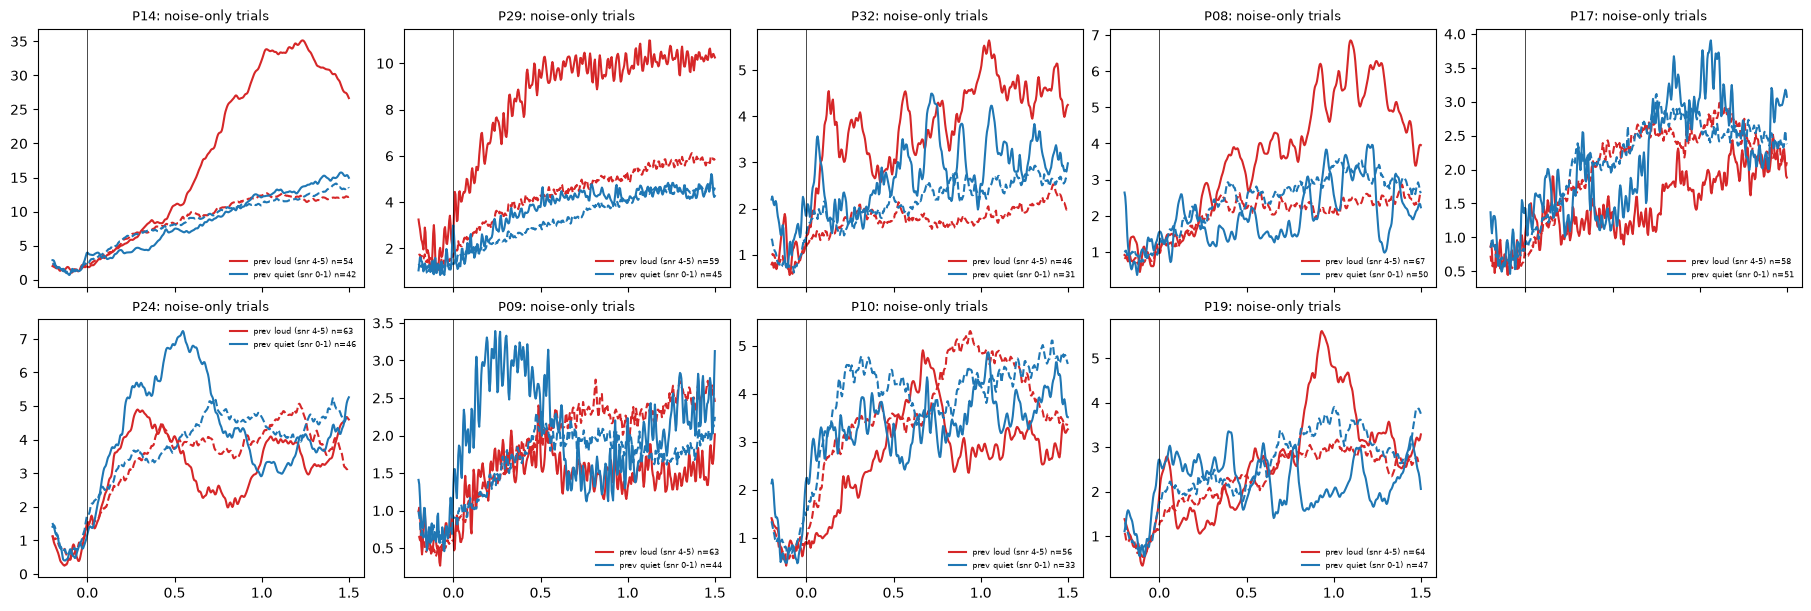

In [16]:
def gfp_and_floor(X, n_perm=20, seed=0):
    rng = np.random.default_rng(seed)
    s = np.r_[np.ones(len(X) // 2), -np.ones(len(X) - len(X) // 2)]
    rms = lambda a: np.sqrt((a ** 2).mean(0)) * 1e6
    fl = np.median([rms((rng.permutation(s)[:, None, None] * X).mean(0)) for _ in range(n_perm)], axis=0)
    return rms(X.mean(0)), fl


def carryover(ep, sub):
    tr = pd.read_csv(repo_root / "Study3" / sub / f"{sub}_trials.tsv", sep="\t").sort_values("trial")
    prev = np.r_[np.nan, tr["snr"].to_numpy()[:-1] - 1.0]
    prev[np.r_[True, np.diff(tr["block"].to_numpy()) != 0]] = np.nan
    md = ep.metadata
    p = md["trial"].map(dict(zip(tr["trial"], prev))).to_numpy()
    rest = (md["snr"] == 0).to_numpy()
    t = ep.times
    X = ep.get_data(picks="eeg")
    X = X - X[:, :, (t >= BL[0]) & (t < BL[1])].mean(-1, keepdims=True)
    return t, {name: (*gfp_and_floor(X[sel]), int(sel.sum()))
               for name, sel in [("prev loud (snr 4-5)", rest & (p >= 4)), ("prev quiet (snr 0-1)", rest & (p <= 1))]}


subs = ["P14", "P29", "P32", "P08", "P17", "P24", "P09", "P10", "P19"]
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, squeeze=False, layout="constrained")
for ax, sub in zip(axes.flat, subs):
    ep = mne.read_epochs(EP_DIR / f"{sub}-epo.fif", preload=True, verbose="error")
    t, out = carryover(ep, sub)
    for (name, (g, fl, n)), col in zip(out.items(), ["tab:red", "tab:blue"]):
        ax.plot(t, g, color=col, label=f"{name} n={n}")
        ax.plot(t, fl, color=col, ls="--")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"{sub}: noise-only trials", fontsize=9)
    ax.legend(fontsize=6, frameon=False)
for ax in axes.flat[len(subs):]:
    ax.axis("off")
plt.show()

Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)


/tmp/ipykernel_570801/691797951.py:11: RuntimeWarning: tmax is not in time interval. tmax is set to <class 'mne.evoked.EvokedArray'>.tmax (1.5 s)
  topo = ev.copy().crop(tp - 0.025, tp + 0.025).data.mean(1) * 1e6


Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)


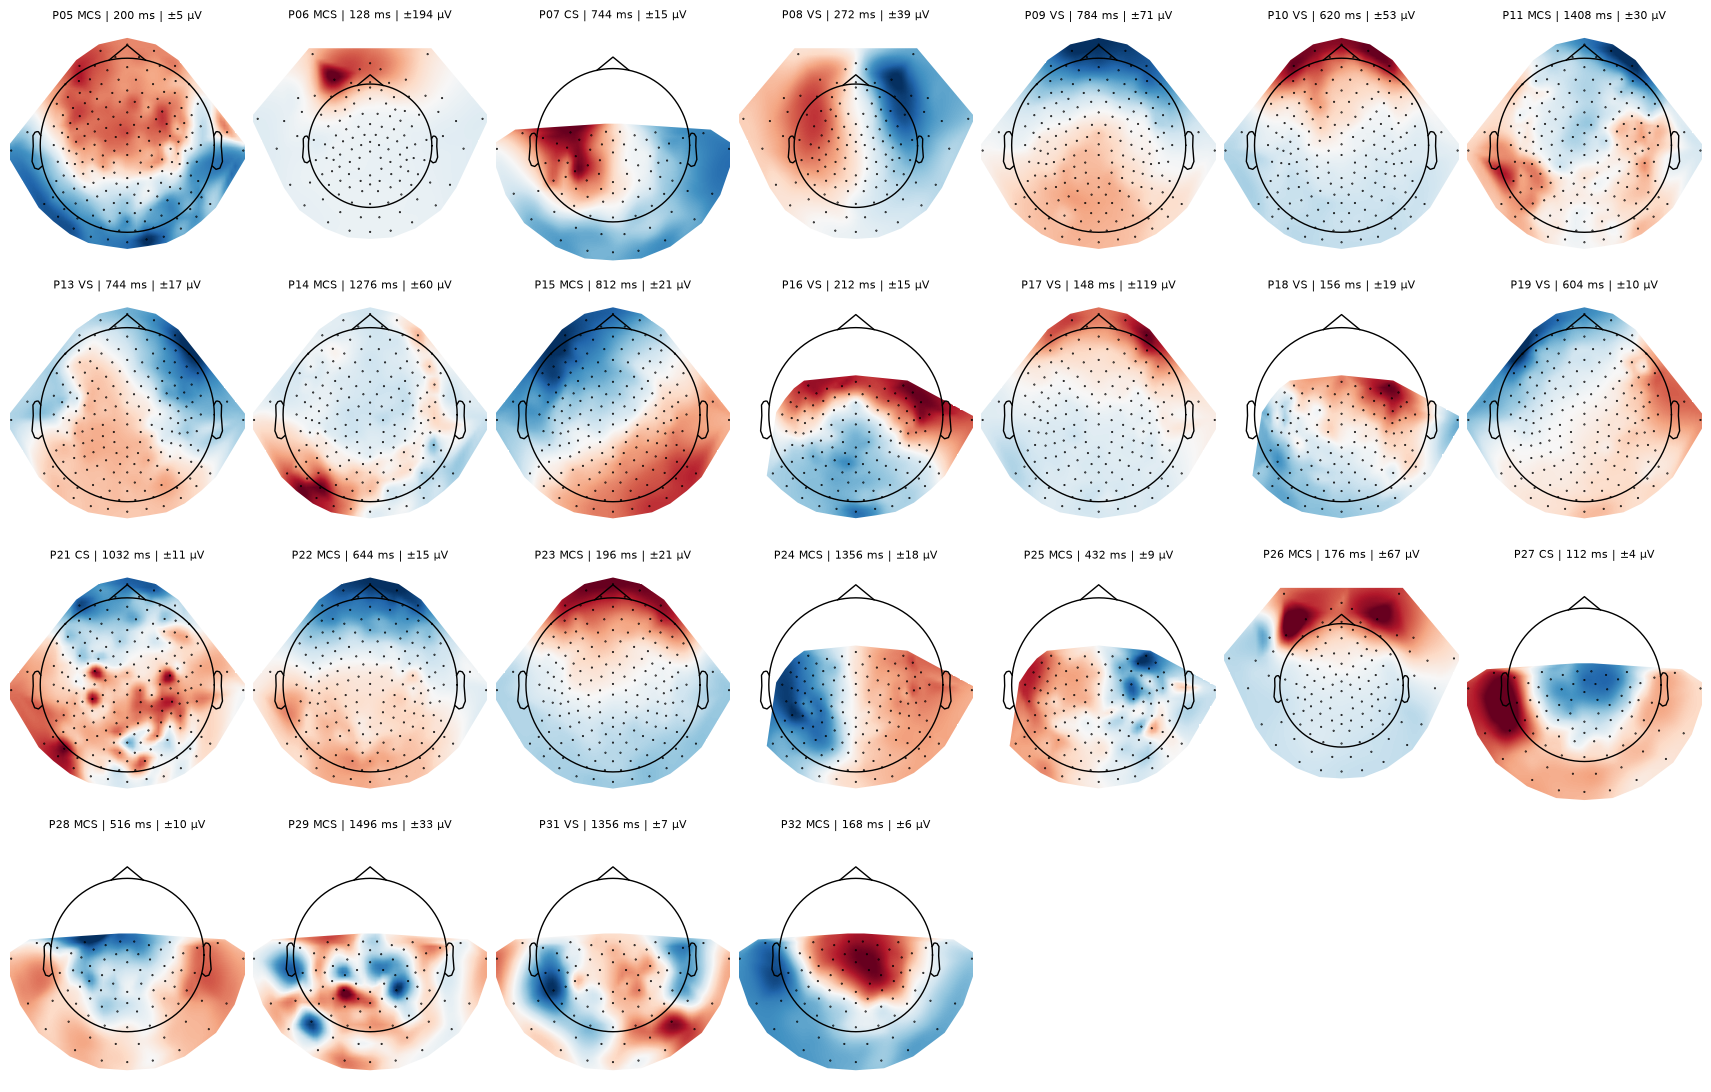

In [17]:
nr = int(np.ceil(len(files) / 7))
fig, axes = plt.subplots(nr, 7, figsize=(17, 2.7 * nr), squeeze=False, layout="constrained")
for ax, f in zip(axes.flat, files):
    sub = f.name.replace("-epo.fif", "")
    ep = mne.read_epochs(f, preload=True, verbose="error")
    ep = ep[((ep.metadata["snr"] == 5) & ~ep.metadata["task_relevant"].astype(bool)).to_numpy()]
    ev = ep.average().apply_baseline(BL)
    gfp = np.sqrt((ev.data ** 2).mean(0))
    w = (ev.times > 0.05) & (ev.times < 1.5)
    tp = ev.times[w][np.argmax(gfp[w])]
    topo = ev.copy().crop(tp - 0.025, tp + 0.025).data.mean(1) * 1e6
    m = np.abs(topo).max()
    mne.viz.plot_topomap(topo, ev.info, axes=ax, show=False, contours=0, cmap="RdBu_r", vlim=(-m, m),
                         sphere="auto", extrapolate="local")
    grp = json.loads((EP_DIR / f"{sub}_qc.json").read_text()).get("group")
    ax.set_title(f"{sub} {grp} | {tp * 1e3:.0f} ms | ±{m:.0f} µV", fontsize=8)
for ax in axes.flat[len(files):]:
    ax.axis("off")
plt.show()